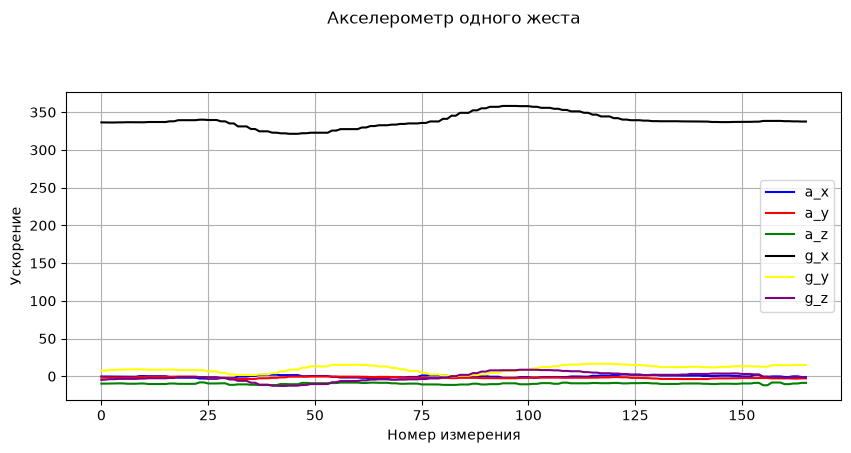

In [50]:
import json
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt
from scipy.signal import buttord, butter, sosfiltfilt
#import scipy
#import sklearn
#import pywt

# создаем путь к нашему датасету
dataset_path = Path(r"C:\Users\Даниил\IIT\task_1\data_legitimate\kovalexal\inf\train")

# получаем список всех текстовых файлов одного пользователя для тренировки 
txt_files = sorted(list(dataset_path.glob("*.txt")))

# функция парсинга тренировочного жеста из файла с номером num_file
# возвращает матрицу измерений (сигналов по горизонтали и временных рядов атрибутов по вертикали)
def get_training_gesture_txt(dataset_path, num_file):
    
    # прочтали текстовый 0-ой файл как json-файл и записали его в виде словаря в file_data
    with open(txt_files[num_file], "r", encoding = "utf-8") as file:
        file_data = json.load(file)
    
    # обращаемся к словарю по двум ключам и получаем все измерения
    measurements = file_data["params"]["data"]
    
    # создаем матрицу измерений размера (кол-во измерений) * 6
    time_series_matrix_list = []
    for measurement in measurements:
        acceleration = measurement["acceleration"]
        rotation = measurement["rotation"]
        # связываем конец первого и начало второго списков
        time_series = acceleration + rotation
        time_series_matrix_list.append(time_series)
    
    # преобразование типов из списка в numpy матричный класс
    time_series_matrix = np.array(time_series_matrix_list, dtype=float)
    return time_series_matrix

# парсим атрибуты (временные ряды) из матрицы для 0-ого файла
time_series_matrix = get_training_gesture_txt(dataset_path, 0)
a_x = time_series_matrix[:, 0]
a_y = time_series_matrix[:, 1]
a_z = time_series_matrix[:, 2]
g_x = time_series_matrix[:, 3]
g_y = time_series_matrix[:, 4]
g_z = time_series_matrix[:, 5]

# строим график временных рядов a_x, a_y, a_z
plt.figure(figsize=(10, 4))

plt.plot(a_x, label="a_x", color="blue")
plt.plot(a_y, label="a_y", color="red")
plt.plot(a_z, label="a_z", color="green")
plt.plot(g_x, label="g_x", color="black")
plt.plot(g_y, label="g_y", color="yellow")
plt.plot(g_z, label="g_z", color="purple")

plt.title("Акселерометр одного жеста\n\n\n")
plt.xlabel("Номер измерения")
plt.ylabel("Ускорение")
plt.grid(True)
plt.legend()

plt.show()



Пытаюсь отфильтровать все 6 временных рядов в одном жесте (фильтр Баттерворта) и построить график для атрибута a_x

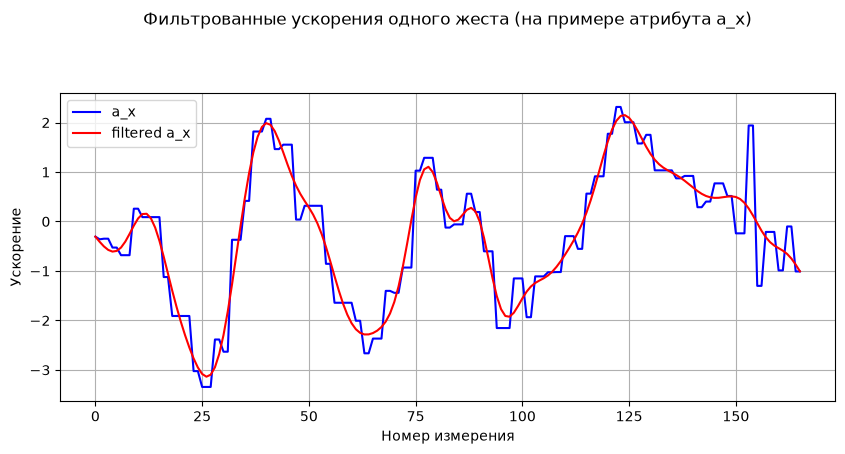

In [45]:
def butterworth_filter_gesture(time_series_matrix):
    wp = 0.17
    ws = 0.30
    gpass = 1
    gstop = 30

    order, cutoff = buttord(wp, ws, gpass, gstop)
    sos = butter(order, cutoff, btype="low", output="sos")
    filtered_matrix = sosfiltfilt(sos, time_series_matrix, axis=0)

    return filtered_matrix

filtered_time_series_matrix = butterworth_filter_gesture(time_series_matrix)
# строим график временных рядов a_x
plt.figure(figsize=(10, 4))

plt.plot(time_series_matrix[:, 0], label="a_x", color="blue")
plt.plot(filtered_time_series_matrix[:, 0], label="filtered a_x", color="red")

plt.title("Фильтрованные ускорения одного жеста (на примере атрибута a_x)\n\n\n")
plt.xlabel("Номер измерения")
plt.ylabel("Ускорение")
plt.grid(True)
plt.legend()

plt.show()


Построим графики всех временных рядов одного пользователя

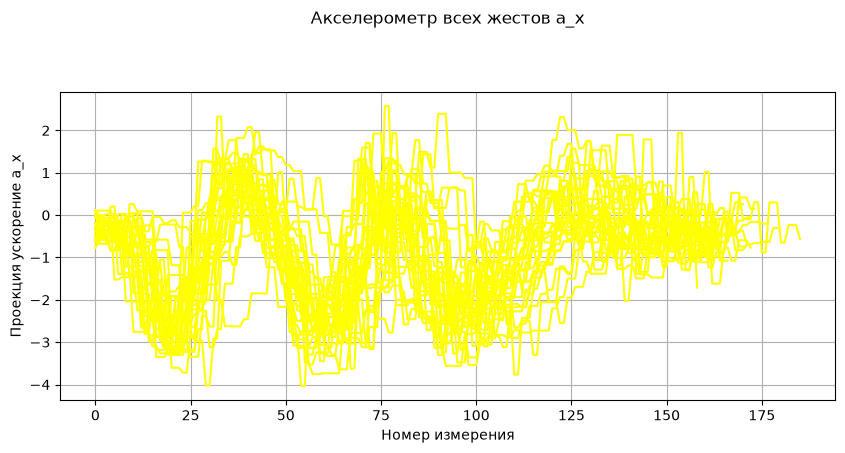

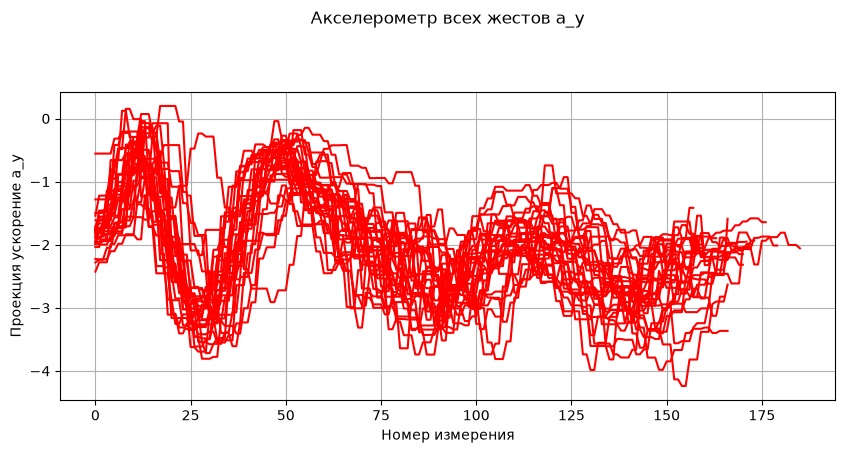

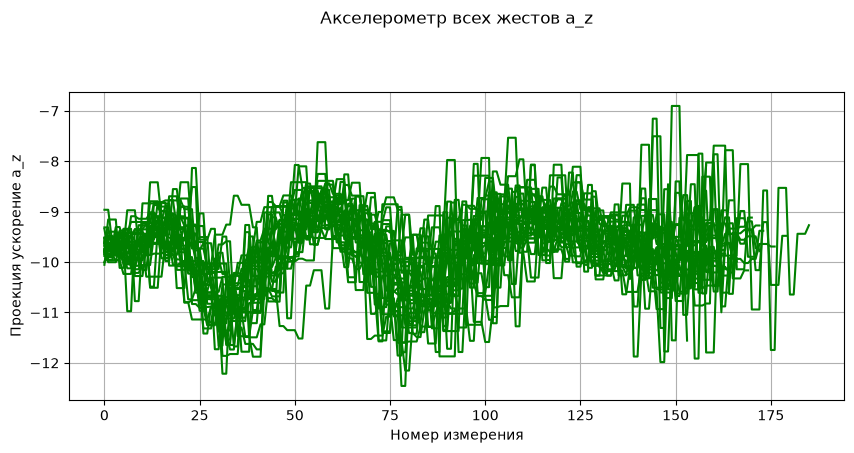

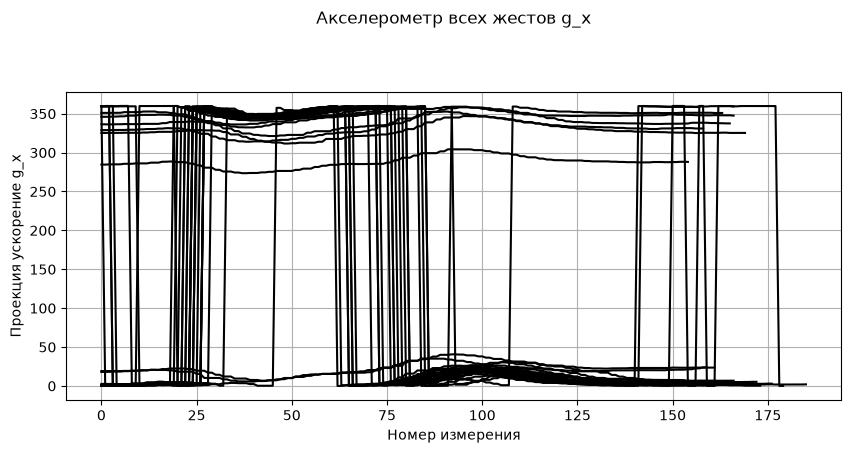

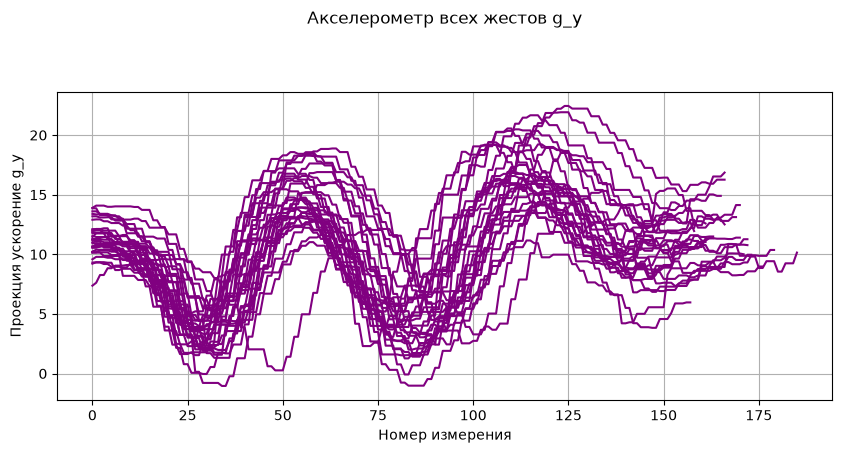

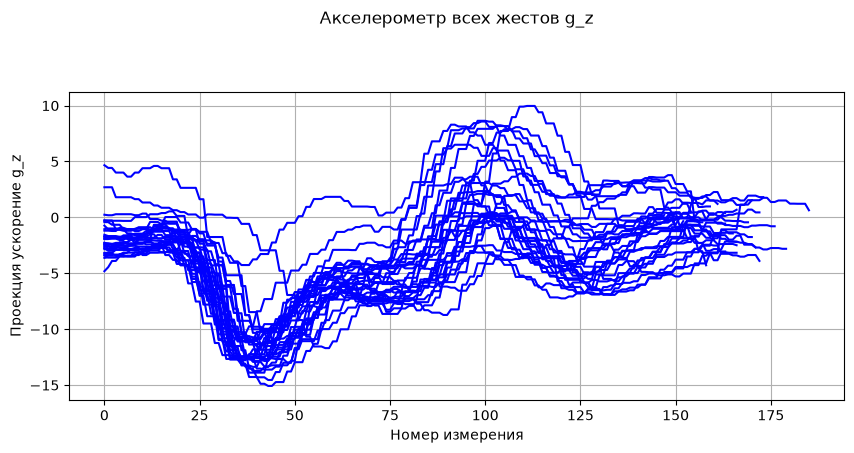

In [46]:
# функция построения графика одной проекций (атрибута/временного ряда) для всех жестов
def build_one_attribute_plot(txt_files, dataset_path, num_time_series, filt):
    plt.figure(figsize=(10, 4))
    match num_time_series:
        case 0:
            attribute_name = "a_x"
            color_name = "yellow"
        case 1:
            attribute_name = "a_y"
            color_name = "red"
        case 2:
            attribute_name = "a_z"
            color_name = "green"
        case 3:
            attribute_name = "g_x"
            color_name = "black"
        case 4:
            attribute_name = "g_y"
            color_name = "purple"
        case 5:
            attribute_name = "g_z"
            color_name = "blue"
        
    for i in range(len(txt_files)):
        # парсим атрибуты (временные ряды) из матрицы для i-ого файла
        time_series_matrix = get_training_gesture_txt(dataset_path, i)
        # если фильтрация не нужна
        if filt == 0:
            attribute = time_series_matrix[:, num_time_series]
            plt.plot(attribute, label=attribute_name, color=color_name)
        # если фильтрация нужна
        else:
            attribute = butterworth_filter_gesture(time_series_matrix[:, num_time_series])
            plt.plot(attribute, label=attribute_name, color=color_name)

    plt.title("Акселерометр всех жестов " + attribute_name + "\n\n\n")
    plt.xlabel("Номер измерения")
    plt.ylabel("Проекция ускорение " + attribute_name)
    plt.grid(True)
    
    plt.show()

# непосредственно строим все графики
amount_all_attributes = 6
for i in range(amount_all_attributes):
    build_one_attribute_plot(txt_files, dataset_path, i, filt=0)

Применим реализованный фильтр Баттерворта ко всем этим рядам

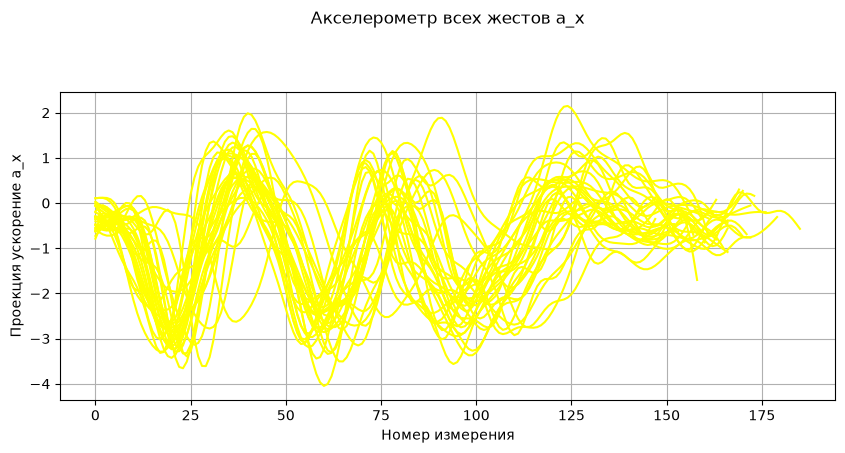

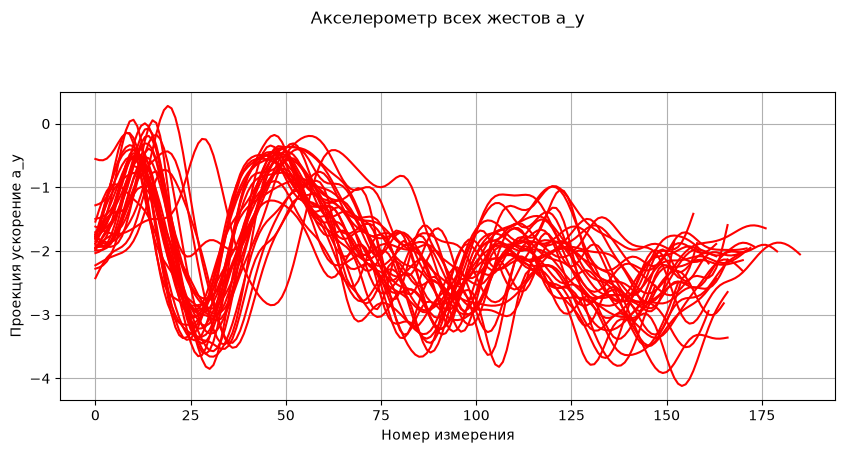

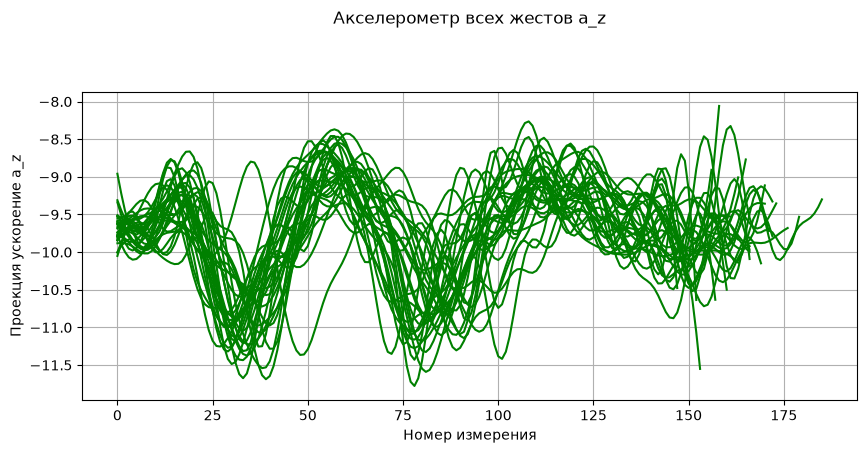

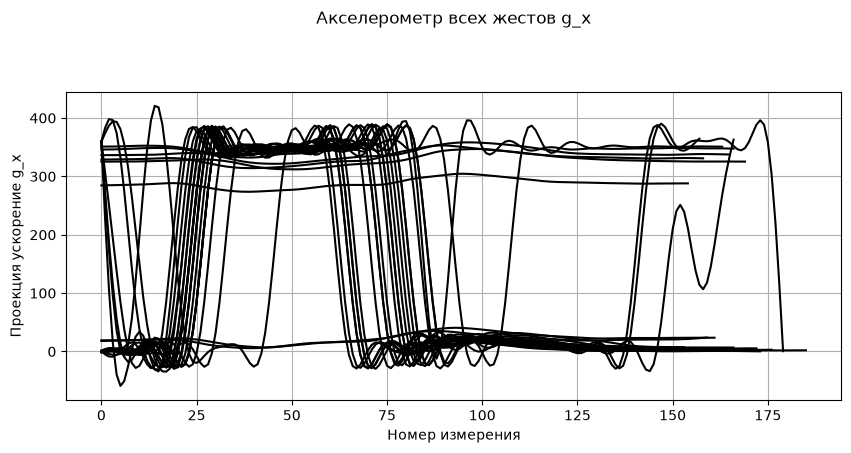

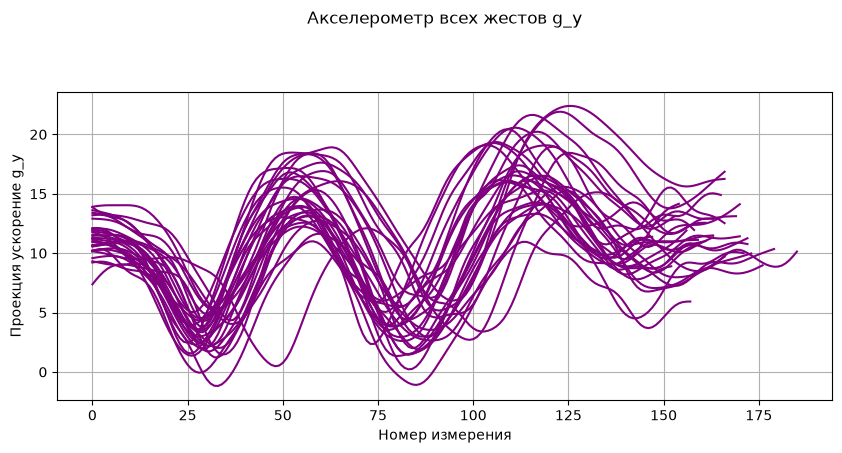

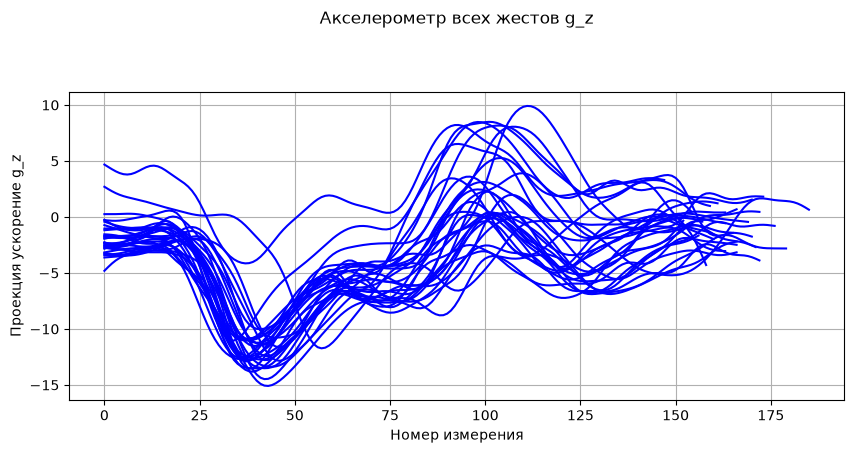

In [48]:
for i in range(amount_all_attributes):
    build_one_attribute_plot(txt_files, dataset_path, i, filt=1)